# Moving Average Crossover Strategy Backtest
This project evaluates historical performance of a 20/50-day Simple Moving Average (SMA) crossover strategy on the SPY ETF, using daily price data from 2015 to 2025. The strategy is benchmarked against buy-and-hold to assess returns, risk-adjusted performance, and market exposure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

### 1. Download historical market data

In [2]:
df = yf.download(
    "SPY",
    start = "2015-01-01",
    end = "2026-01-01",
    auto_adjust = True # adjusts OHLC prices for splits and dividends
)

close = df["Close"].squeeze()

print(df.head())
print(df.shape)

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2015-01-02  169.267502  170.462264  168.237543  170.050280  121465900
2015-01-05  166.210602  168.394109  165.905738  168.229318  169632600
2015-01-06  164.645050  167.034549  163.854036  166.515446  209151400
2015-01-07  166.696793  167.034622  165.518526  165.963462  125346700
2015-01-08  169.654785  169.869025  168.081018  168.097488  147217800
(2766, 5)


### 2. Visualise stock price

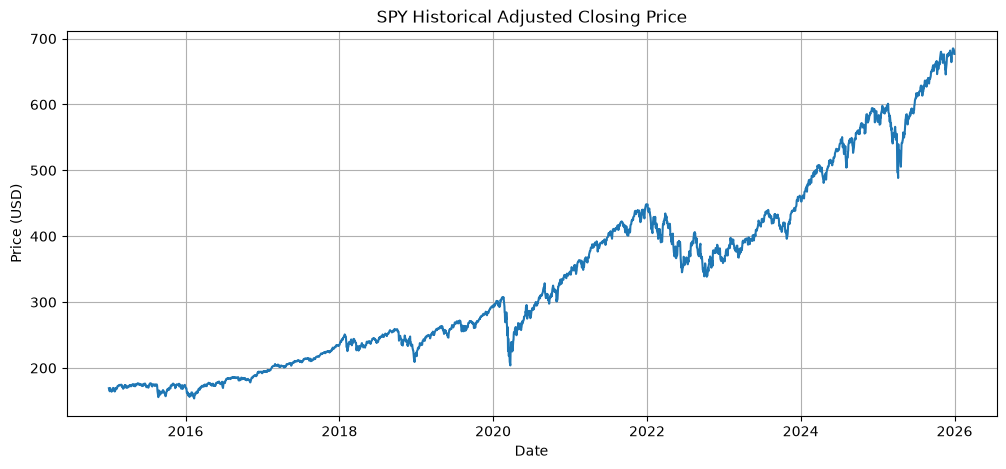

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(close)

plt.title("SPY Historical Adjusted Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True)
plt.show()

### 3. Calculate simple moving averages
- 20-day SMA: Shorter-term price trends, reacts faster to recent price movements
- 50-day SMA: Longer-term price trends, smoother
  
When shorter average rises above longer average, suggests that recent prices are relatively stronger than long-term trend.

Note: MA are lagging indicators, they summarise historical prices rather than predicting future prices.

In [4]:
df["SMA20"] = close.rolling(window=20).mean()
df["SMA50"] = close.rolling(window=50).mean()

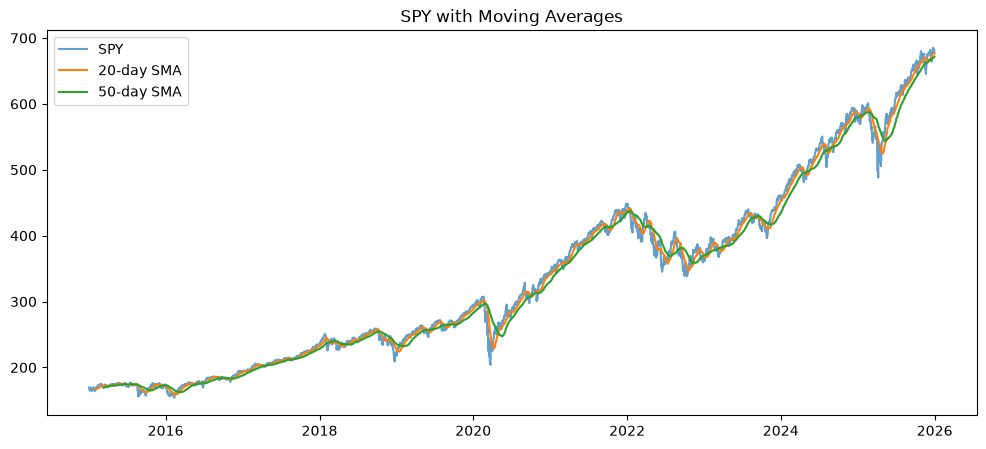

In [5]:
# plot indicators
plt.figure(figsize=(12, 5))

plt.plot(close, label="SPY", alpha=0.7)
plt.plot(df["SMA20"], label="20-day SMA")
plt.plot(df["SMA50"], label="50-day SMA")

plt.legend()
plt.title("SPY with Moving Averages")
plt.show()

### 4. Generate trading signals
Strategy (long only):
- SMA20 > SMA50: Hold SPY (buy / hold SPY)
- SMA20 ≤ SMA50: Hold cash (sell SPY / hold cash)
  
Signal is shifted to avoid look-ahead bias since closing price is used.


In [6]:
# indicator function
df["Signal"] = (df["SMA20"] > df["SMA50"]).astype(int)

# take positions after signal observed
df["Position"] = df["Signal"].shift(1).fillna(0)

### 5. Calculate strategy returns
Backtesting assumptions:
- **Execution:** Signals are lagged by one trading period, with returns calculated using a simplified close-to-close model. Actual execution prices are not simulated.
- **Positions:** The strategy alternates between 100% SPY and 100% cash, with no short selling, borrowing, or leverage.
- **Cash:** Uninvested cash earns zero interest.
- **Transaction Costs:** Commissions, spreads, and slippage are excluded from gross returns. Proportional transaction costs are incorporated separately in Section 10.

In [7]:
# SPY daily return (today's price vs yesterday's price)
df["Market_Return"] = close.pct_change()

# strategy daily return (position * SPY daily return) - strategy only earns SPY returns when invested
df["Strategy_Return"] = (df["Position"] * df["Market_Return"])

df[["Market_Return", "Strategy_Return"]].head()

Price,Market_Return,Strategy_Return
Ticker,,
Date,,
2015-01-02,NaN,NaN
2015-01-05,-0.018060,-0.0
2015-01-06,-0.009419,-0.0
2015-01-07,0.012462,0.0
2015-01-08,0.017745,0.0


### 6. Compare against buy-and-hold
Compares growth of $1 invested in each strategy.

In [8]:
# first valid SMA50 date
first_valid = df["SMA50"].first_valid_index()
start_pos = df.index.get_loc(first_valid) + 1 # start trading one day later

# restrict both strategies to the same evaluation period
returns = df.iloc[start_pos:][["Market_Return", "Strategy_Return"]].dropna()

# compound returns to obtain cumulative growth of investment
equity = (1 + returns).cumprod() # cumulative product

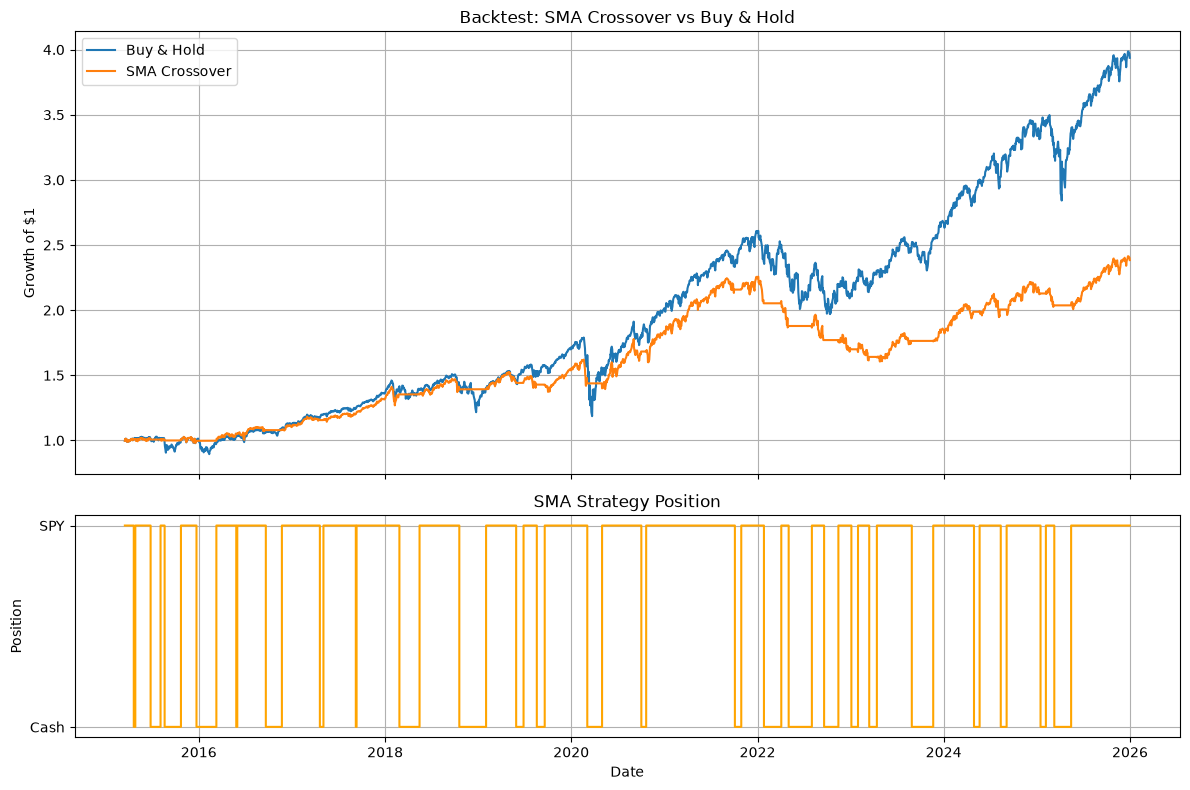

In [9]:
fig, axes = plt.subplots(2, 1,figsize=(12, 8),sharex=True,gridspec_kw={"height_ratios": [2, 1]})

# top: equity curves
axes[0].plot(equity.index,equity["Market_Return"],label="Buy & Hold")
axes[0].plot(equity.index,equity["Strategy_Return"],label="SMA Crossover")

axes[0].set_title("Backtest: SMA Crossover vs Buy & Hold")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
axes[0].grid(True)

# bottom: strategy position
axes[1].step(equity.index,df.loc[equity.index, "Position"],where="post",color="orange",label="SMA Position")

axes[1].set_title("SMA Strategy Position")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Position")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Cash", "SPY"])
axes[1].grid(True)

plt.tight_layout()
plt.savefig("results/sma_crossover.png", dpi=300, bbox_inches="tight")
plt.show()

### 7. Evaluate strategy performance 
- **CAGR:** Annualised compounded growth rate
- **Annualised volatility:** Standard deviation of daily returns, annualised
- **Sharpe ratio (annualised):** Excess return per unit of volatility (zero risk-free interest rate assumed)
- **Maximum drawdown:** Worst peak-to-trough loss
- **Average market exposure:** Proportion of time strategy is invested in SPY

In [10]:
def performance_metrics(returns):
    returns = returns.dropna()
    equity = (1 + returns).cumprod()

    cagr = equity.iloc[-1] ** (252 / len(returns)) - 1
    volatility = returns.std() * np.sqrt(252)
    sharpe = (returns.mean() / returns.std() * np.sqrt(252) if returns.std() > 0 else np.nan)
    drawdown = equity / equity.cummax() - 1

    return {
        "CAGR": cagr,
        "Volatility": volatility,
        "Sharpe": sharpe,
        "Max Drawdown": drawdown.min(),
    }

In [11]:
results = pd.DataFrame({
    "Buy & Hold": performance_metrics(returns["Market_Return"]),
    "SMA Crossover": performance_metrics(returns["Strategy_Return"])
}).T

results["Avg Exposure"] = [1.0,df.loc[returns.index, "Position"].mean()] # time in market

print(results.round(3))

                CAGR  Volatility  Sharpe  Max Drawdown  Avg Exposure
Buy & Hold     0.136       0.179   0.802        -0.337         1.000
SMA Crossover  0.084       0.113   0.769        -0.289         0.718


### 8. Performance Decomposition

#### 8.1 Return Attribution
Decomposes SPY daily returns into periods where strategy was invested vs holding cash. Missed upside and avoided downside are calculated as arithmetic sums of daily returns rather than compounded portfolio returns.

In [12]:
position = df.loc[returns.index, "Position"]
market_returns = returns["Market_Return"]

captured = market_returns.where(position == 1, 0) # market returns during invested periods
missed = market_returns.where(position == 0, 0) # market returns during cash periods

missed_upside = missed.clip(lower=0).sum()
avoided_downside = -missed.clip(upper=0).sum()

print(f"Captured daily returns (sum): {captured.sum():.2%}")
print(f"Missed daily returns (sum): {missed.sum():.2%}")
print(f"Missed upside (sum): {missed_upside:.2%}")
print(f"Avoided downside (sum): {avoided_downside:.2%}")

Captured daily returns (sum): 93.84%
Missed daily returns (sum): 60.45%
Missed upside (sum): 443.30%
Avoided downside (sum): 382.85%


#### 8.2 Constant Exposure Benchmark
Compares SMA strategy against portfolio maintaining constant allocation to SPY equal to strategy's average market exposure, with remainder held in cash and rebalanced daily. Assesses whether differences in performance are attributed to market timing or reduced exposure.

In [13]:
avg_exposure = position.mean()
returns["Constant_Exposure"] = (avg_exposure * returns["Market_Return"])

exposure_comparison = pd.DataFrame({
    "Buy & Hold": performance_metrics(returns["Market_Return"]),
    "SMA Crossover": performance_metrics(returns["Strategy_Return"]),
    "Constant Exposure": performance_metrics(returns["Constant_Exposure"])
}).T

display(
    exposure_comparison.style.format({
        "CAGR": "{:.2%}",
        "Volatility": "{:.2%}",
        "Sharpe": "{:.3f}",
        "Max Drawdown": "{:.2%}"
    })
)

,CAGR,Volatility,Sharpe,Max Drawdown
Buy & Hold,13.56%,17.85%,0.802,-33.72%
SMA Crossover,8.40%,11.32%,0.769,-28.89%
Constant Exposure,9.92%,12.82%,0.802,-25.12%


### 9. Trade-level Performance
Only includes positions with complete entry-to-exit history within evaluation window. Excludes initial partial trade and final open trade.

In [14]:
# identify position changes
trades = position.diff().fillna(0)

num_buys = (trades == 1).sum()
num_sells = (trades == -1).sum()

print("Buys:", num_buys)
print("Sells:", num_sells)
print("Total transactions:", num_buys + num_sells)

Buys: 25
Sells: 25
Total transactions: 50


In [15]:
trade_records = []

entry_date = None
entry_idx = None

for i, date in enumerate(position.index):

    current_position = position.iloc[i]

    previous_position = (
        position.iloc[i - 1] if i > 0
        else current_position
    )

    # entry: 0 -> 1
    if current_position == 1 and previous_position == 0:
        entry_date = date
        entry_idx = i

    # exit: 1 -> 0
    elif current_position == 0 and previous_position == 1:

        # only record trades entered within evaluation period
        if entry_idx is not None:
            trade_returns = market_returns.iloc[entry_idx:i]

            total_return = (
                (1 + trade_returns).prod() - 1
            )

            trade_records.append({
                "Entry Date": entry_date,
                "Exit Date": date,
                "Trade Return": total_return,
                "Holding Days": i - entry_idx
            })

        entry_date = None
        entry_idx = None

trade_df = pd.DataFrame(trade_records)

In [16]:
def trade_performance(trade_df):

    num_trades = len(trade_df) 
    
    winning_trades = trade_df[trade_df["Trade Return"] > 0]
    losing_trades = trade_df[trade_df["Trade Return"] < 0]
    win_rate = len(winning_trades) / num_trades if num_trades > 0 else np.nan

    avg_win = winning_trades["Trade Return"].mean() # avg return on winning trades
    avg_loss = losing_trades["Trade Return"].mean() # avg return on losing trades
    avg_holding = trade_df["Holding Days"].mean()

    position_changes = position.diff().fillna(0)
    annual_turnover = position_changes.abs().sum() / len(position) * 252

    return pd.Series({
    "Completed Trades": num_trades,
    "Win Rate": win_rate,
    "Avg Winning Trade": avg_win,
    "Avg Losing Trade": avg_loss,
    "Avg Holding Period": avg_holding,
    "Annual Turnover": annual_turnover
    })

trade_performance(trade_df)

Completed Trades      24.000000
Win Rate               0.583333
Avg Winning Trade      0.079491
Avg Losing Trade      -0.033086
Avg Holding Period    73.666667
Annual Turnover        4.639175
dtype: float64

### 10. Transaction Cost Analysis
Assumes one fixed proportional cost per transaction at 10 bps.

In [17]:
position_changes = position.diff() # detect position changes
position_changes.iloc[0] = 0 # assume initial position already established
traded_fraction = position_changes.abs() # traded portfolio fraction (1/0 in this case)

In [18]:
cost_bps = 10
cost_rate = cost_bps / 10000

returns["Strategy_Net"] = (returns["Strategy_Return"] - cost_rate * traded_fraction)

In [19]:
comparison = pd.DataFrame({
    "SMA Gross": performance_metrics(returns["Strategy_Return"]),
    "SMA Net": performance_metrics(returns["Strategy_Net"]),
    "Buy & Hold": performance_metrics(returns["Market_Return"])
}).T

print(comparison.round(4))

              CAGR  Volatility  Sharpe  Max Drawdown
SMA Gross   0.0840      0.1132  0.7692       -0.2889
SMA Net     0.0789      0.1132  0.7279       -0.2960
Buy & Hold  0.1356      0.1785  0.8020       -0.3372


### 11. Interpretation of Results

#### Key Findings
- **Performance:** The SMA crossover strategy underperformed buy-and-hold, generating a CAGR of 8.4% vs. 13.6% and a lower Sharpe ratio (0.769 vs. 0.802), before transaction costs.
- **Risk & Market Exposure:** The SMA strategy exhibited lower volatility (11.3% vs. 17.9%). However, the constant-exposure benchmark (71.8% SPY) achieved a higher Sharpe ratio (0.802 vs. 0.769) and a smaller maximum drawdown (25.1% vs. 28.9%), suggesting limited evidence of superior market timing.
- **Return Attribution:** The strategy missed 443.3% in cumulative arithmetic positive daily-return contributions while avoiding 382.9% in negative contributions during cash periods. This suggests that missed upside outweighed avoided downside.
- **Trade-Level Performance:** Across 24 completed trades, the strategy achieved a 58.3% win rate, with average winning and losing returns of +7.95% and −3.31%, respectively. Average holding period was 73.7 trading days, with annual turnover of approximately 4.64×.
- **Transaction Costs:** At 10 bps per transaction, CAGR declined from 8.40% to 7.89%, while the Sharpe ratio fell from 0.769 to 0.728.

#### Limitations
- Simplified close-to-close execution assumptions may differ from realistically executable prices.
- Transaction costs are approximated using a fixed proportional rate; actual slippage, spreads, and market impact are not modelled separately.
- Uninvested cash earns zero interest, and the Sharpe ratio assumes a zero risk-free rate.
- No out-of-sample validation or parameter robustness testing has been conducted.

#### Conclusion
The SMA crossover strategy reduced volatility relative to buy-and-hold but underperformed in both absolute and risk-adjusted returns. Its lower volatility appears partly attributable to reduced market exposure, while transaction costs further weakened performance. The constant-exposure benchmark achieved higher returns and a better Sharpe ratio, suggesting that dynamically switching between SPY and cash based on SMA signals did not improve overall risk-adjusted performance.